# Перенос устойчивости от шума к задержке

**Результат:** гипотеза общего улучшения не подтвердилась. При задержке 2 шага среднее E = -37.09, выборочное стандартное отклонение между 3 seed = 71.01. На двух seed эффект небольшой положительный, на одном существенно отрицательный.

## Постановка

Трек 1. Помогает ли шум наблюдений при обучении уменьшить потерю качества управления маятником при задержке наблюдений во время оценки?

Гипотеза: при одинаковом бюджете агент с шумом потеряет меньше средней награды при задержке на 2 шага. Возможная причина: меньшая чувствительность к ошибкам измерения. Это предположение, независимый шум и устаревшие наблюдения различаются.

Используется стандартный Pendulum-v1: наблюдение `[cos(theta), sin(theta), omega]`, действие от -2 до 2 Н·м, награда `-(theta² + 0.1 omega² + 0.001 torque²)`. Угол нормализован в пределах от -π до π, ноль соответствует вертикали. Награда штрафует отклонение, скорость и усилие. Эпизод заканчивается через 200 шагов по `truncated`, достижение вертикали не завершает его. Шаг 0.05 с, длительность эпизода 10 с.

## Условия

Готовый SAC, MLP 64×64, CPU, один поток PyTorch, 30 000 шагов на модель. Learning rate 0.0003, batch size 256, buffer size 100000, learning starts 100, gamma 0.99, tau 0.005, одно обновление за шаг, автоматический коэффициент энтропии. Итоговый checkpoint последний.

`clean` обучается на обычных наблюдениях. `noisy` получает независимый гауссов шум угла 0.05 рад и скорости 0.1 рад/с. Косинус и синус пересчитываются из зашумлённого угла, скорость ограничивается диапазоном от -8 до 8 рад/с. Отдельный генератор шума не меняет физику, награду и последовательность начальных состояний.

При оценке шум отключён. Наблюдение задерживается на 0, 1, 2, 4 шага, то есть 0, 0.05, 0.10, 0.20 с. Действия не задерживаются, история при сбросе заполняется начальным наблюдением.

Seed обучения: 42, 43, 44. Промежуточная оценка: 200-204. Тест: 1000-1019, по 20 эпизодов на модель и задержку. Пилот использовал seed обучения 0, 1, 2 и оценки 100-104. Тест не использовался для настройки. Всего 6 моделей и 480 тестовых эпизодов, плюс 20 эпизодов случайной политики.

Оборудование: Apple M1 Max, 64 ГиБ, macOS 26.2, Python 3.13.1. Время одного основного запуска 56.70-57.33 с, всех запусков 341.81 с, включая промежуточную оценку. Linux/Colab не проверен.

Ноутбук читает сохранённые результаты и не запускает обучение. Команды воспроизведения и описание пилота находятся в [README](../README.md).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
results = root / "results"
data = results / "main"
summary = pd.read_csv(data / "summary.csv")
runs = pd.read_csv(data / "runs.csv")
effects = pd.read_csv(data / "effects.csv")
episodes = pd.read_csv(data / "episodes.csv")

## Обучение

Слева для каждого seed сначала рассчитано скользящее среднее последних 10 обучающих эпизодов, в начале используются все доступные эпизоды. Затем показано среднее по 3 seed. Справа сначала усредняются 5 чистых оценочных эпизодов каждого запуска, затем 3 seed, сглаживания нет. Полосы на обоих графиках: среднее ± выборочное стандартное отклонение между seed, не доверительный интервал.

Обучающие награды у noisy измерены при шумных наблюдениях, поэтому промежуточная оценка в одинаковой чистой среде даёт более сопоставимую картину.

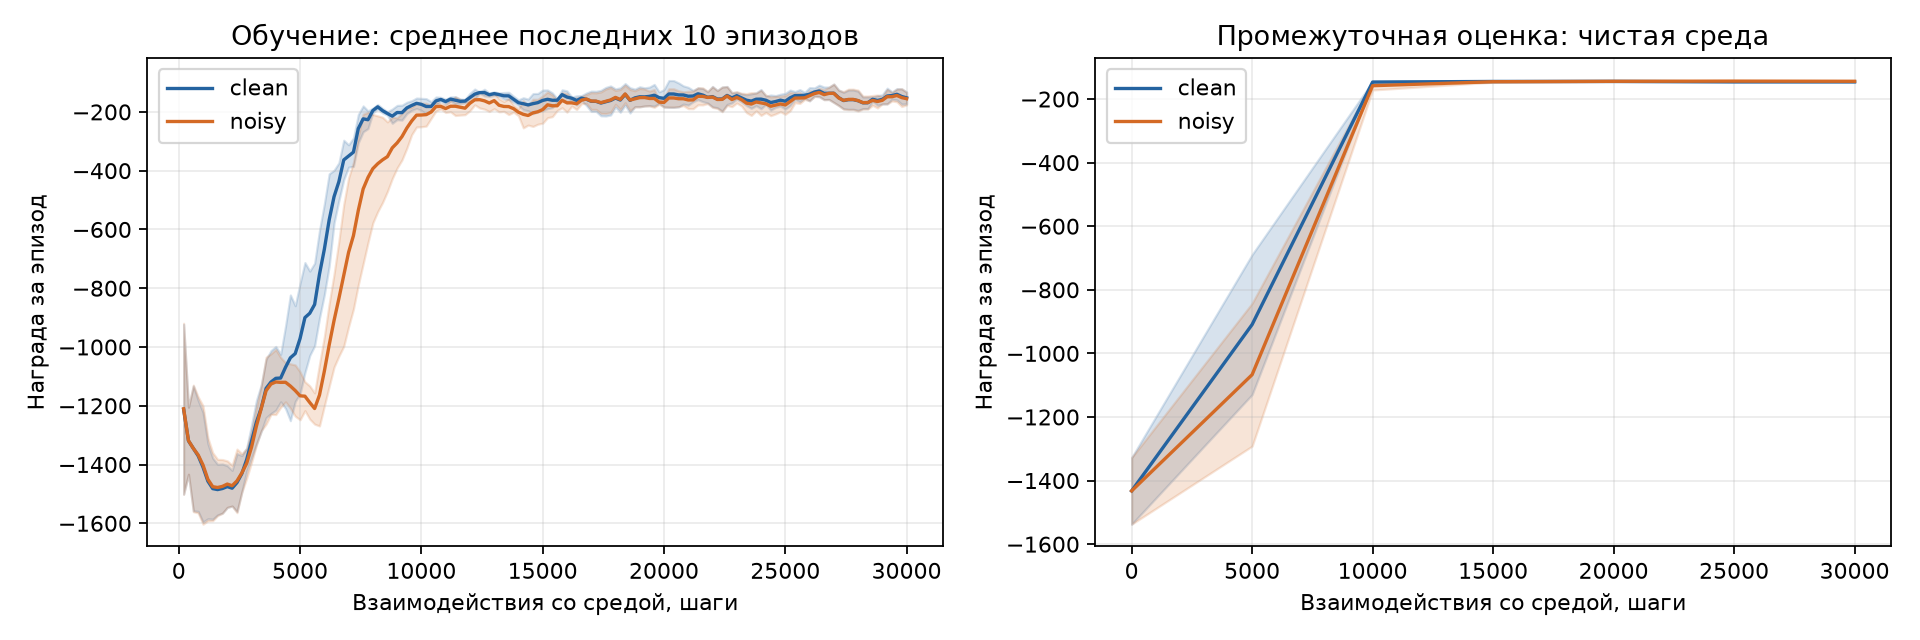

In [2]:
display(Image(filename=str(results / "figures/learning.png")))

## Итоговое сравнение

`R_c,s(d)` - средняя награда 20 эпизодов одного запуска. `D_c,s(d) = R_c,s(0) - R_c,s(d)` - потеря. `E_s = D_clean,s(2) - D_noisy,s(2)` - основное сравнение, положительное значение соответствует гипотезе.

В таблице и на графике разброс рассчитан по 3 средним отдельных запусков, а не по 60 независимым повторам обучения. Процентное падение отрицательной награды не используется. Линия случайной политики показывает её среднюю награду в чистой среде, а не результат проверки на всех задержках.

,condition,delay,reward_mean,reward_std,loss_mean,loss_std,seeds
0,clean,0,-151.425,1.068,0.000,0.000,3
1,clean,1,-153.716,0.560,2.291,0.566,3
2,clean,2,-159.526,1.532,8.101,1.348,3
3,clean,4,-924.130,233.928,772.705,233.604,3
4,noisy,0,-149.731,1.110,0.000,0.000,3
5,noisy,1,-151.329,1.332,1.598,0.328,3
6,noisy,2,-194.926,72.263,45.195,71.865,3
7,noisy,4,-890.904,108.171,741.173,108.736,3


,condition,train_seed,delay,reward,episodes,baseline_reward,loss
0,clean,42,0,-152.190,20,-152.190,0.000
1,clean,42,1,-153.935,20,-152.190,1.745
2,clean,42,2,-161.278,20,-152.190,9.088
3,clean,42,4,-1176.961,20,-152.190,1024.771
4,clean,43,0,-150.205,20,-150.205,0.000
5,clean,43,1,-153.080,20,-150.205,2.874
6,clean,43,2,-158.854,20,-150.205,8.649
7,clean,43,4,-880.052,20,-150.205,729.847
8,clean,44,0,-151.880,20,-151.880,0.000
9,clean,44,1,-154.133,20,-151.880,2.253


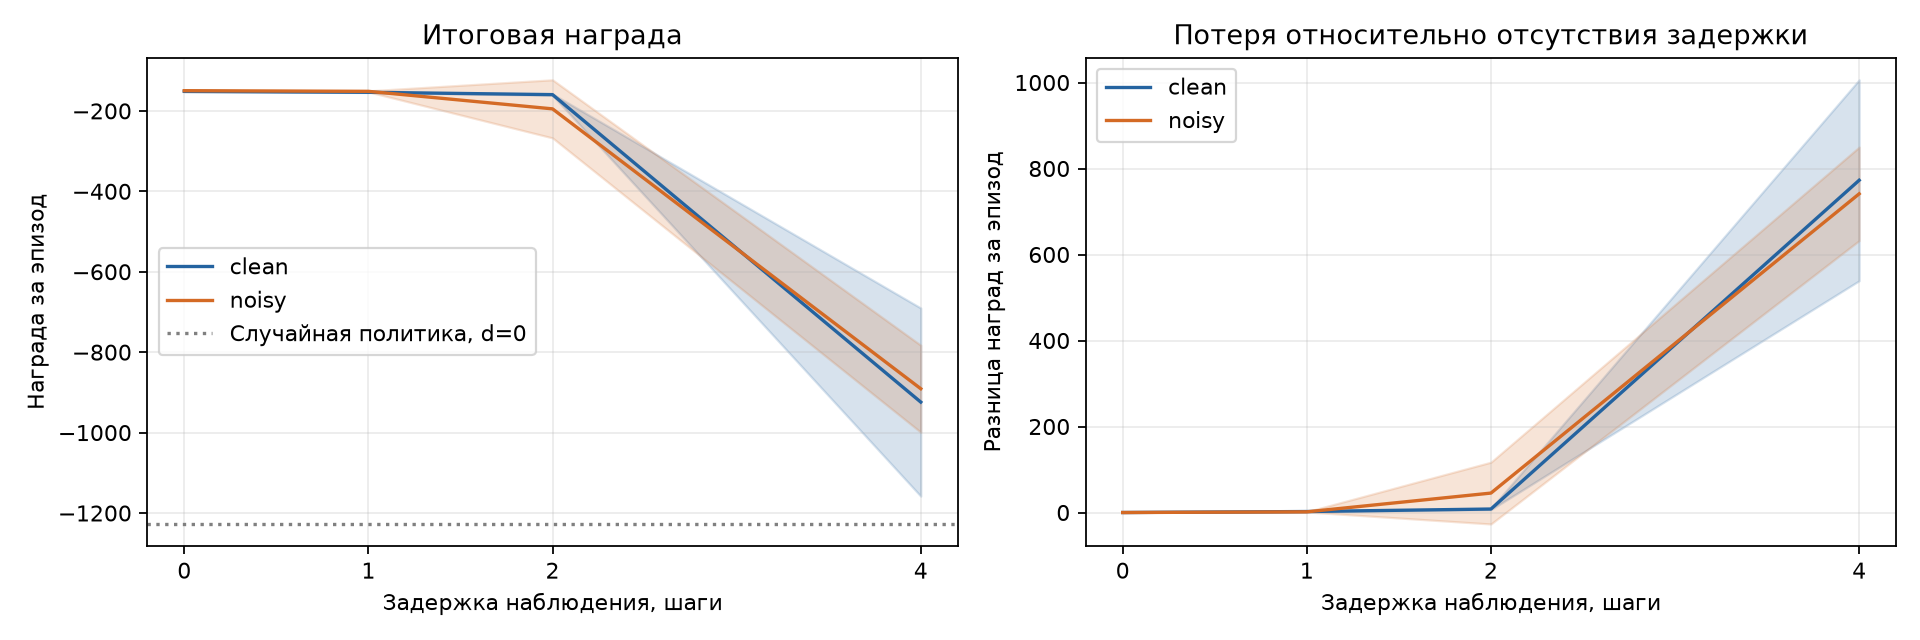

,train_seed,clean,noisy,effect
0,42,9.088,128.173,-119.085
1,43,8.649,4.400,4.249
2,44,6.565,3.010,3.554


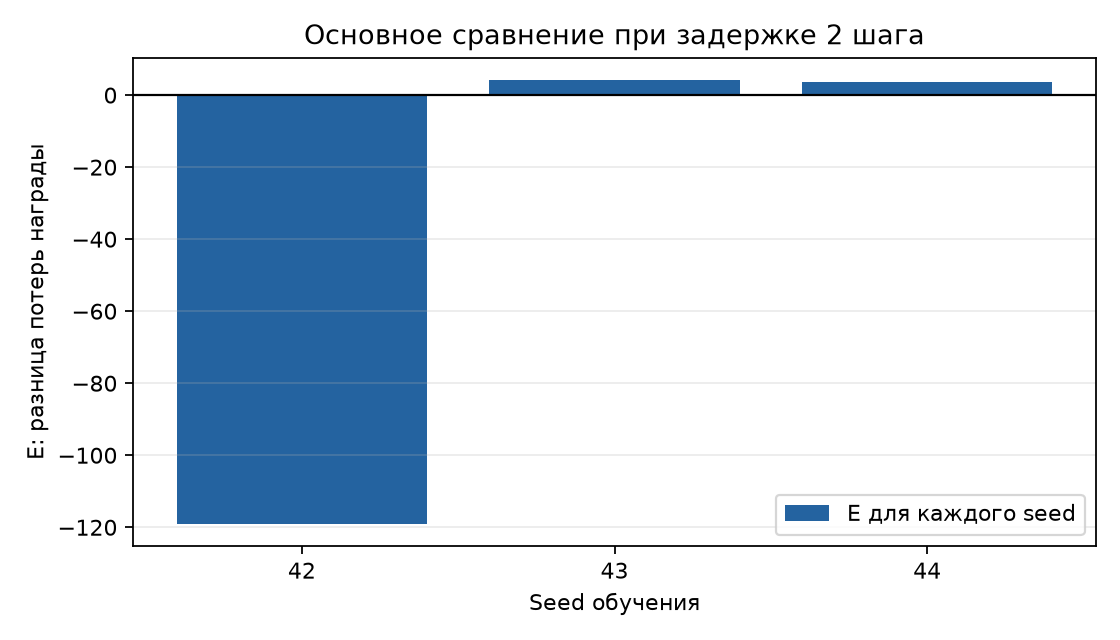

In [3]:
display(summary.round(3))
display(runs.round(3))
display(Image(filename=str(results / "figures/delay.png")))
display(effects.round(3))
display(Image(filename=str(results / "figures/effects.png")))

Без задержки clean получает -151.43, noisy -149.73 против -1227.27 у случайной политики. Обучение работоспособно. При d=2 награда clean равна -159.53 ± 1.53, noisy -194.93 ± 72.26. Потери равны 8.10 и 45.19 соответственно.

E для seed 42, 43, 44: -119.08, 4.25, 3.55. Среднее отрицательное, знаки различаются. Поэтому общего подтверждения гипотезы нет. Низкая потеря не объясняется слабым исходным качеством: обе конфигурации без задержки близки, noisy немного лучше.

При d=4 качество резко снижается: -924.13 ± 233.93 и -890.90 ± 108.17. Это дополнительное сравнение с большим разбросом, оно не заменяет основной результат при d=2.

## Ошибки и зависимость от начального состояния

У noisy с seed обучения 42 три эпизода при d=2 имеют награды ниже -1000. Они выделены после оценки для разбора ошибки, не исключены из метрик и не использованы для изменения настроек.

In [4]:
paired = episodes[(episodes.train_seed == 42) & (episodes.delay == 2)].pivot(
    index="episode_seed", columns="condition", values="reward"
)
paired["noisy_minus_clean"] = paired.noisy - paired.clean
display(paired.loc[[1002, 1004, 1015]].round(3))

condition,clean,noisy,noisy_minus_clean
episode_seed,,,
1002,-134.084,-1037.690,-903.607
1004,-357.834,-1003.383,-645.549
1015,-133.640,-1005.022,-871.383


Три эпизода дают вклад -121.03 в среднюю разницу noisy минус clean по 20 эпизодам, тогда как полная разница равна -117.07. Остальные эпизоды частично компенсируют этот провал. Поэтому среднее скрывает сильную зависимость результата от начального состояния.

Большой отрицательный return сам по себе не доказывает конкретный механизм сбоя. Возможные объяснения: чувствительность конкретной выученной политики к задержке, различия траекторий обучения, небольшой набор seed. Утверждать, что шум систематически ухудшает устойчивость, тоже нельзя.

## Поведение на заранее выбранном эпизоде

Seed модели 42, seed эпизода 2000, выбранные до тестирования. Показаны обе конфигурации при d=0 и d=2. Анимации идут в модельном времени, по 10 с. Этот эпизод не входит в тестовые 20 и не иллюстрирует три найденных провала.

График использует истинный угол перед действием. Скачок от π к -π является переходом нормализованного угла через границу, а не физическим скачком маятника.

Дополнительный разбор после итоговой оценки: для модели с seed 42 при d=2 в эпизодах 1002, 1004, 1015 среднеквадратичный нормализованный угол на последних 100 шагах составил у clean 0.175, 0.177, 0.177 рад, у noisy 1.513, 1.518, 1.490 рад. Доля этих шагов с |theta| < 0.2 рад равна 59%, 59%, 58% и 12%, 11%, 12% соответственно. Угол измерен перед действием. Это указывает на плохое удержание около вертикали, а не только на различия затрат управления. Порог 0.2 рад выбран для описания поведения после теста и не является заранее заданной метрикой успеха или основанием проверки гипотезы.

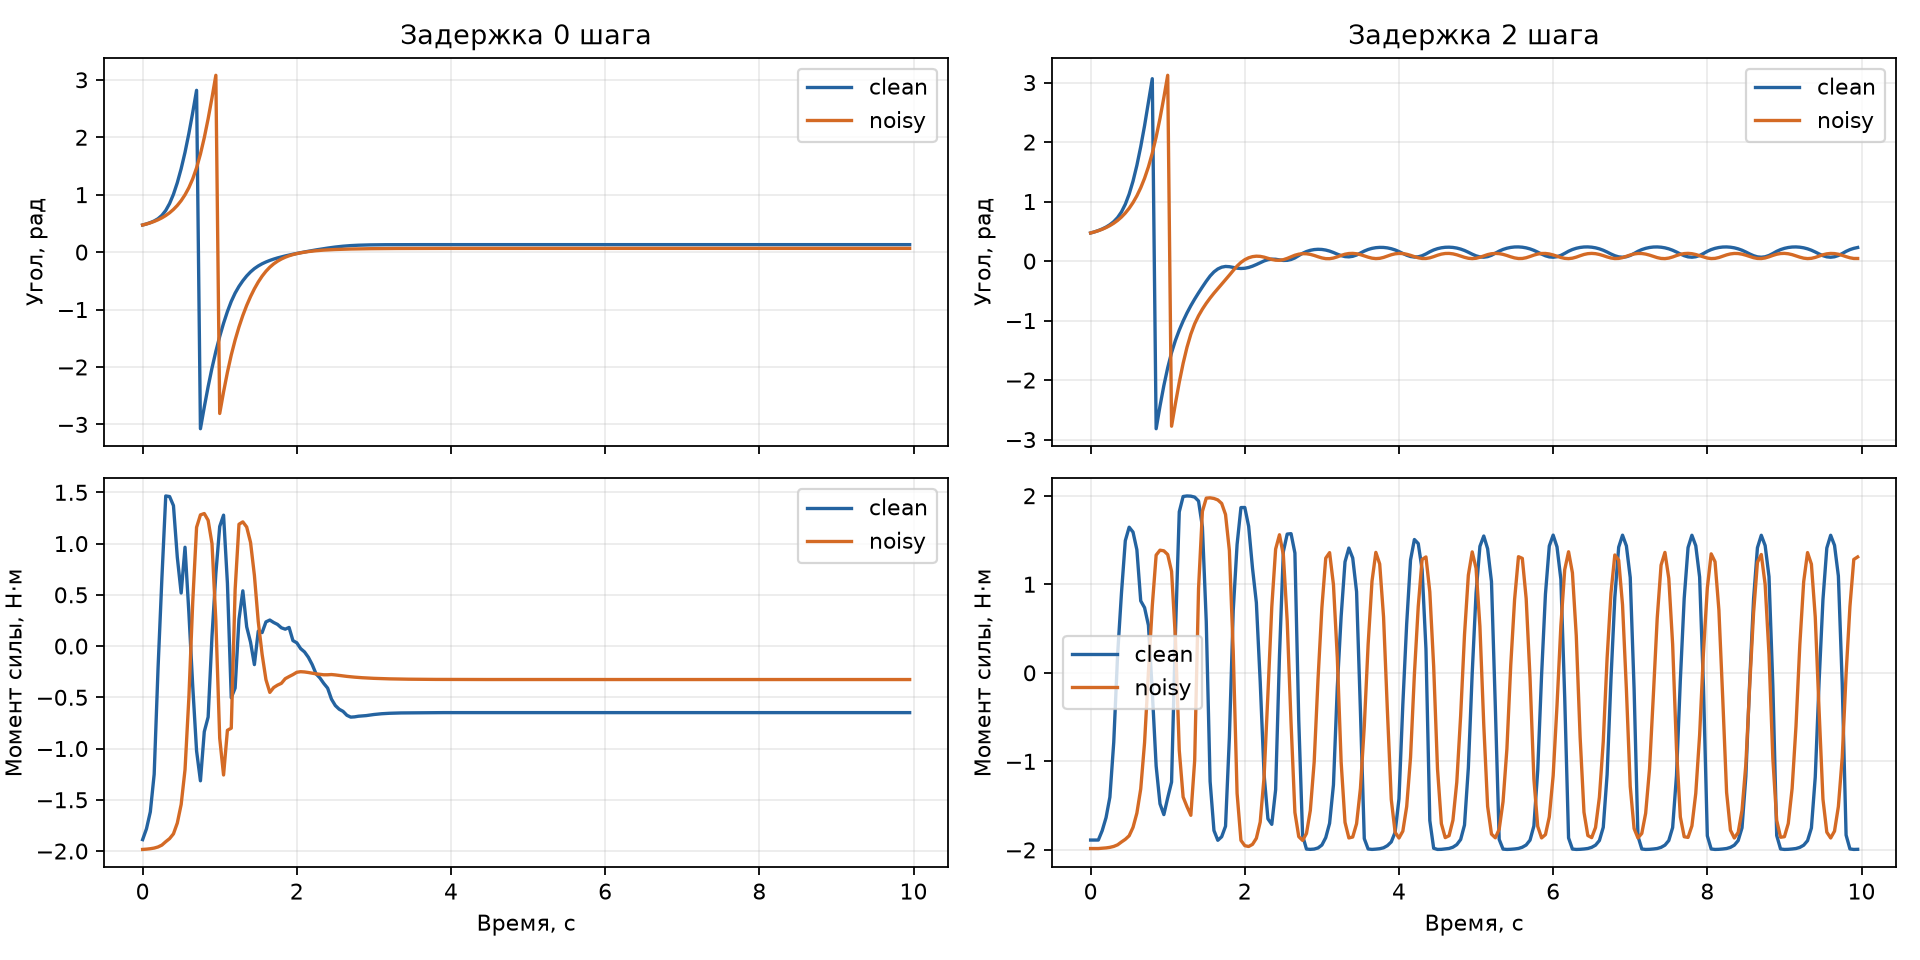

In [5]:
display(Image(filename=str(results / "animations/behavior.png")))

Обе модели поднимают маятник и удерживают его около вертикали. При d=2 сохраняются колебания и растёт усилие. За последние 5 с среднеквадратичный момент clean увеличивается с 0.65 до 1.61 Н·м, noisy с 0.33 до 1.28 Н·м. Среднеквадратичный угол увеличивается с 0.130 до 0.170 рад и с 0.065 до 0.092 рад соответственно. Это описание одного заранее выбранного эпизода, а не общий вывод об устойчивости.

### clean, без задержки

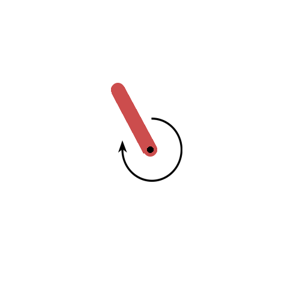

In [6]:
display(Image(filename=str(results / "animations/clean_delay_0.gif")))

### clean, задержка 2 шага

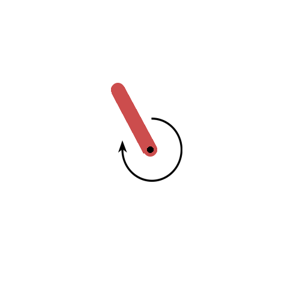

In [7]:
display(Image(filename=str(results / "animations/clean_delay_2.gif")))

### noisy, без задержки

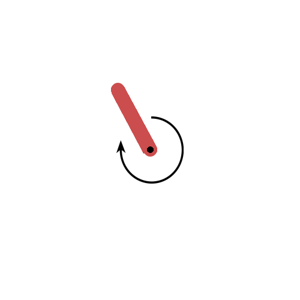

In [8]:
display(Image(filename=str(results / "animations/noisy_delay_0.gif")))

### noisy, задержка 2 шага

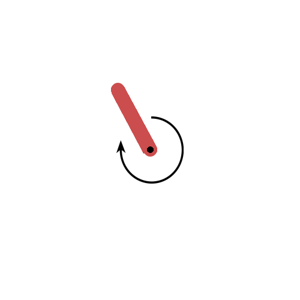

In [9]:
display(Image(filename=str(results / "animations/noisy_delay_2.gif")))

## Вывод и ограничения

При выбранных параметрах перенос устойчивости от шума к задержке 2 шага не подтверждён: E = -37.09 ± 71.01, noisy уступает и по абсолютной средней награде. Два небольших положительных эффекта не компенсируют провал третьего seed. Все запуски сохранены.

Ограничения: одна среда, SAC с одной архитектурой, 3 seed обучения, 20 тестовых начальных состояний и один уровень шума. Политика без памяти получает устаревшее наблюдение, что отличается от независимой погрешности измерения. Статистическая значимость и причинный механизм не установлены. Пять пилотных эпизодов могли не выявить редкие неудачи, а демонстрационный эпизод не показывает весь спектр ошибок.

Следующий самостоятельный эксперимент мог бы увеличить число seed и начальных состояний, затем проверить историю наблюдений или другой уровень шума на новом тестовом наборе. В текущем эксперименте настройки после теста не менялись.

Графики пересоздаются командой `python -m src.plots`, анимации командой `python -m src.render` из корня проекта. Для анимаций нужны локальные модели в `artifacts/`, для просмотра этого ноутбука и готовых изображений они не нужны. Полный снимок зависимостей и метаданные находятся в `results/main/evaluation.json`.